# Worked examples over the sample of the cregit token dataset

This notebook reads the sample in `data/` with pandas and pyarrow, and at the end with DuckDB.
The sample has 36 whole project files of the release (see `SAMPLE.md`). Each row is one token of
the source code, with the commit and the person (a pseudonym) that last changed it.

The notebook prints only counts, shares, organization ids and pseudonyms. It never prints a
name, an address, a domain, a commit message or code text.

In [1]:
import os
import pandas as pd
import pyarrow.parquet as pq
import load  # load.py, next to this notebook

DATA = "data"
files = load.project_files(DATA)
print(len(files), "project files")

36 project files


## 1. The schema and the footer of one file

In [2]:
f = os.path.join(DATA, "parquet", "google__guava-dataset.parquet")
pf = pq.ParquetFile(f)
print("rows:", pf.metadata.num_rows, " row groups:", pf.metadata.num_row_groups, " columns:", pf.metadata.num_columns)
print("created by:", pf.metadata.created_by)
schema = pd.DataFrame({"column": pf.schema_arrow.names, "type": [str(t) for t in pf.schema_arrow.types]})
schema.index += 1
schema

rows: 4101399  row groups: 5  columns: 71
created by: parquet-cpp-arrow version 26.0.1


,column,type
1,repo_name,string
2,clone_url,string
3,provenance_status,string
4,source,string
5,stratum,string
...,...,...
67,footer_person_names,list<element: string>
68,firm_based_on_namespace,string
69,firm_based_on_domain,string
70,project_enterprise_driven,bool


In [3]:
# The five key-value entries of the footer.
{k.decode(): v.decode() for k, v in pf.metadata.metadata.items()}

{'pseudonymization_registry_sha256': 'ca284a4e1b9fcb69a28bd2709083ef5d546f488559db273307c3f14cc23d9580',
 'pseudonymization_version': '2',
 'organizations_mapping_sha256': '7b52a5155e6f9af60541d5cdfaf6ef6566679a1281497ab274decadb50debe62',
 'organizations_version': 'v4.9',
 'ctp_schema_version': '2'}

## 2. The projects of the sample

`load.load_projects` reads the row count from each footer and the project columns from the first
row. The commit layer comes from the column `commits`.

In [4]:
projects = load.load_projects(files)
print(f"{len(projects)} projects, {projects['rows'].sum():,} rows, {projects['bytes'].sum():,} bytes")
pd.crosstab(projects["stratum"], [projects["layer"], projects["language"]], margins=True)

36 projects, 45,553,409 rows, 247,500,886 bytes


layer          1,000 to 4,999 commits               5,000 or more commits      \
language                            C C++ Java Rust                     C C++   
stratum                                                                         
company                             1   1    1    1                     1   1   
contested                           0   1    0    0                     0   1   
fiscal-sponsor                      0   0    0    1                     1   0   
foundation                          1   1    1    1                     1   1   
personal                            1   1    1    1                     1   1   
unknown                             1   1    1    1                     1   1   
All                                 4   5    4    5                     5   5   

layer                    All  
language       Java Rust      
stratum                       
company           1    1   8  
contested         0    0   2  
fiscal-sponsor    0    0   2  
foundation        1    1   8  
personal          1    1   8  
unknown           1    1   8  
All               4    4  36

In [5]:
orgs = load.load_organizations(DATA)
pd.Series({t: len(df) for t, df in orgs.items()}, name="rows")

organizations               9343
organization_domains       10899
organization_namespaces     7061
project_organizations      10763
link_error                   108
release_info                  20
Name: rows, dtype: int64

## 3. Read the rows of one project

Read only the columns that you need. `is_structural = 1` marks a boundary marker of the
tokenizer; `is_structural = 0` is a code token.

In [6]:
cols = ["file_path", "token_index", "token_type", "is_structural", "author_date",
        "personid", "firm_based_on_domain", "firm_based_on_namespace"]
df = pq.read_table(f, columns=cols).to_pandas()
print(df.shape)
df[df.is_structural == 0].head(5)

(4101399, 8)


,file_path,token_index,token_type,is_structural,author_date,personid,firm_based_on_domain,firm_based_on_namespace
2,android/guava-testlib/src/com/google/common/co...,2,comment,0,2017-04-20 21:33:38,author 30293bfc55ebec,google,google
7,android/guava-testlib/src/com/google/common/co...,7,package,0,2017-04-20 21:33:38,author 30293bfc55ebec,google,google
8,android/guava-testlib/src/com/google/common/co...,8,name,0,2017-04-20 21:33:38,author 30293bfc55ebec,google,google
9,android/guava-testlib/src/com/google/common/co...,9,operator,0,2017-04-20 21:33:38,author 30293bfc55ebec,google,google
10,android/guava-testlib/src/com/google/common/co...,10,name,0,2017-04-20 21:33:38,author 30293bfc55ebec,google,google


## 4. Who wrote the surviving code of the project?

The share of code tokens by organization of the author address (`firm_based_on_domain`), and
by author pseudonym (`personid`).

In [7]:
kinds = orgs["organizations"].set_index("organization_id")["kind"]
code_tokens = df[df.is_structural == 0]
by_org = code_tokens["firm_based_on_domain"].value_counts()
t = pd.DataFrame({"kind": by_org.index.map(kinds), "tokens": by_org,
                  "percent": (100 * by_org / by_org.sum()).round(2)})
t.head(8)

,kind,tokens,percent
firm_based_on_domain,,,
google,company,3727374,96.82
free-provider,free-provider,112555,2.92
unknown,unknown,3118,0.08
epam-systems,company,2193,0.06
independent,independent,1913,0.05
intershop-communications,company,837,0.02
amazon,company,756,0.02
meta,company,431,0.01


In [8]:
by_person = code_tokens["personid"].value_counts()
pd.DataFrame({"tokens": by_person, "percent": (100 * by_person / by_person.sum()).round(2)}).head(5)

,tokens,percent
personid,,
author 30293bfc55ebec,1514171,39.33
author 6f1a70359c24f6,589617,15.32
author 147036345603e3,479853,12.46
author 76a7a2b028f8a0,240648,6.25
author f645f8220e9b7a,165475,4.30


In [9]:
# The "insider" share: the author address has the organization that controls the account.
(code_tokens["firm_based_on_domain"] == code_tokens["firm_based_on_namespace"]).mean().round(4)

np.float64(0.9682)

## 5. All sample files: the kind of the organization of the author address

`load.count_values` reads one column in batches of 1,000,000 rows, so the same code also runs
on the full release (`python load.py --data <release root>`).

In [10]:
by_org_all = load.count_values(files, "firm_based_on_domain")
by_kind = by_org_all.groupby(by_org_all.index.map(lambda i: kinds.get(i, "(not in the table)"))).sum()
load.share(by_kind.sort_values(ascending=False))

,tokens,percent
company,18884555,44.15
free-provider,11939378,27.91
independent,5009937,11.71
foundation,2710299,6.34
unknown,2236909,5.23
project,1338379,3.13
academic,289448,0.68
consultancy,203714,0.48
government,81438,0.19
nonprofit,51173,0.12


## 6. Code tokens by the year of the author date, for each commit layer

The year of the commit that last changed each surviving token. The chart gives the share of the
code tokens of each layer, so the two layers use one scale.

In [11]:
rows = []
for layer, group in projects.groupby("layer"):
    fl = [os.path.join(DATA, "parquet", p + load.SUFFIX) for p in group["project"]]
    s = load.count_values(fl, "author_date", load.year_of)
    rows.append(pd.DataFrame({"layer": layer, "year": s.index.astype(int), "tokens": s.values}))
years = pd.concat(rows)
years["percent"] = 100 * years["tokens"] / years.groupby("layer")["tokens"].transform("sum")
table = years.pivot(index="year", columns="layer", values="percent").fillna(0).round(2)
table.tail(12)

layer,"1,000 to 4,999 commits","5,000 or more commits"
year,,
2015,4.99,2.41
2016,6.23,2.25
2017,7.33,7.80
2018,4.76,2.77
2019,5.04,2.30
2020,2.21,3.27
2021,8.32,3.25
2022,5.21,4.54
2023,9.36,4.64


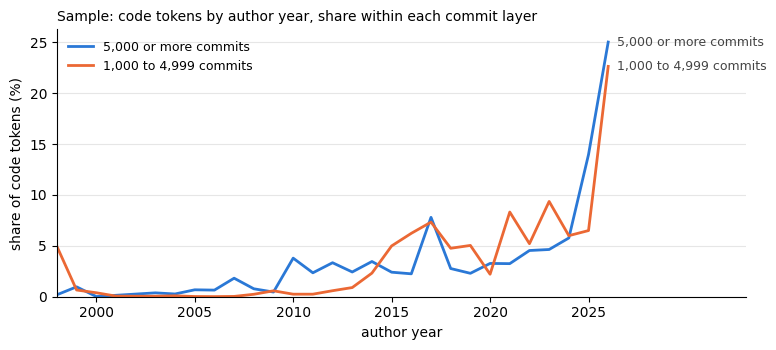

In [12]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("matplotlib is not installed; the table above has the same values")

if plt is not None:
    colors = {"5,000 or more commits": "#2a78d6", "1,000 to 4,999 commits": "#eb6834"}
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for layer, color in colors.items():
        s = table[layer]
        ax.plot(s.index, s.values, color=color, linewidth=2, label=layer)
        ax.annotate(layer, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color="#444444")
    ax.set_ylabel("share of code tokens (%)")
    ax.set_xlabel("author year")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    ax.set_title("Sample: code tokens by author year, share within each commit layer", fontsize=10, loc="left")
    ax.set_xlim(table.index.min(), table.index.max() + 7)
    ax.set_xticks([y for y in range(1995, 2030, 5) if table.index.min() <= y <= table.index.max()])
    fig.tight_layout()
    plt.show()

## 7. DuckDB over the views of `dataset.duckdb` (optional)

The views use paths relative to the folder that holds `parquet/` and `organizations/`, so the
code opens the file from `data/`.

In [13]:
try:
    import duckdb
except ImportError:
    duckdb = None
    print("duckdb is not installed: pip install duckdb")

if duckdb is not None:
    here = os.getcwd()
    os.chdir(DATA)
    con = duckdb.connect("organizations/dataset.duckdb", read_only=True)
    print(con.sql("SELECT count(*) AS stale_files FROM stale_files").df().to_string(index=False))
    print()
    print(con.sql("""
        SELECT namespace_organization_kind, domain_organization_kind, count(*) AS tokens,
               round(100.0 * count(*) / sum(count(*)) OVER (PARTITION BY namespace_organization_kind), 2) AS percent
        FROM tokens_with_organizations
        WHERE is_structural = 0
        GROUP BY 1, 2
        QUALIFY row_number() OVER (PARTITION BY namespace_organization_kind ORDER BY count(*) DESC) <= 3
        ORDER BY 1 NULLS LAST, 3 DESC""").df().to_string(index=False))

 stale_files
           0

namespace_organization_kind domain_organization_kind   tokens  percent
                    company                  company 13003088    69.05
                    company              independent  2088402    11.09
                    company            free-provider  1788971     9.50
                 foundation               foundation  2705173    45.32
                 foundation                  company  2369043    39.69
                 foundation              independent   497558     8.34
                    project            free-provider  4328840    60.18
                    project              independent  1724282    23.97
                    project                  company  1079084    15.00
                       None            free-provider  5438925    50.45
                       None                  company  2433340    22.57
                       None                  project  1325624    12.30


In [14]:
if duckdb is not None:
    # The expected share of wrong firm_based_on_domain values in one project (the query of docs/ERROR.md).
    print(con.sql("""
        SELECT avg(coalesce(p_error,
                   CASE WHEN firm_based_on_domain = 'independent'
                        THEN (SELECT estimate FROM link_error WHERE error_stratum LIKE 'fallback/independent%')
                        ELSE 0 END)) AS expected_error
        FROM tokens_with_current_organizations
        WHERE project = 'google__guava'""").df().to_string(index=False))
    print()
    # The sample projects that a foundation hosts (relation hosted_by).
    print(con.sql("""
        SELECT h.project, h.hosted_by, h.hosted_by_kind, p.firm_based_on_namespace
        FROM project_hosts h JOIN project_organizations p USING (project)
        WHERE h.project IN (SELECT DISTINCT regexp_extract(filename, '([^/]+)-dataset\\.parquet$', 1) FROM tokens)
        ORDER BY 1""").df().to_string(index=False))
    con.close()
    os.chdir(here)

 expected_error
       0.000506

                project                         hosted_by hosted_by_kind firm_based_on_namespace
     Dstack-TEE__dstack                  linux-foundation     foundation                  dstack
mavlink__qgroundcontrol                  linux-foundation     foundation                 mavlink
       nmstate__nmstate                  linux-foundation     foundation                 nmstate
       nmstate__nmstate cloud-native-computing-foundation     foundation                 nmstate
